# 基差策略的交易成本

沿用基差打分和持仓规则，只改变交易成本。先算每天换了多少仓，再看每成交十万元扣0、20、50、100元时，净值有什么变化。

本文件夹可以单独使用，只读取自己的 data。安装 numpy、pandas、matplotlib 和 jupyterlab，在本章目录打开 notebook，从上到下运行。

样例包含16个商品、2024年下半年，与基差入门篇相同。不代表完整历史或样本外表现，也不用于复现视频中的年化数字。


## 推荐阅读

1. [A Taxonomy of Anomalies and Their Trading Costs](https://doi.org/10.1093/rfs/hhv063) — Robert Novy-Marx、Mihail Velikov，The Review of Financial Studies，2016。讨论股票策略交易成本，供理解研究方法，不用于确定本例期货费率。
2. [An Anatomy of Commodity Futures Risk Premia](https://doi.org/10.1111/jofi.12096) — Marta Szymanowska 等，The Journal of Finance，2014。延伸了解商品期货风险溢价。


## 读数据 选合约

market.csv 是合约日行情，basis.csv 是同日同合约的基差率。用前一天持仓量最大的合约作为当天代表合约，避免使用当天尚未知道的持仓量。


In [1]:
# 首次使用，请先在终端安装：python -m pip install numpy pandas matplotlib jupyterlab
# 在本章目录启动 Jupyter，打开这份 notebook，从上到下运行。
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('data')
market = pd.read_csv(DATA / 'market.csv', parse_dates=['date'])
assert not market.duplicated(['date', 'contract']).any()
assert market['close'].gt(0).all()
dates = pd.DatetimeIndex(sorted(market['date'].unique()))
prices = market.pivot(index='date', columns='contract', values='close').reindex(dates)
interest = market.pivot(index='date', columns='contract', values='open_interest').reindex(dates)

# 昨天持仓量最大的合约，作为今天的代表合约。
lag_interest = interest.shift(1).stack().rename('lag_interest').reset_index()
lag_interest.columns = ['date', 'contract', 'lag_interest']
selected = market.merge(lag_interest, on=['date', 'contract'], how='inner')
selected = selected.sort_values(['date', 'symbol', 'lag_interest', 'contract'])
selected = selected.drop_duplicates(['date', 'symbol'], keep='last')
grid = pd.MultiIndex.from_product([dates, sorted(market.symbol.unique())], names=['date', 'symbol'])
panel = selected.set_index(['date', 'symbol']).reindex(grid).reset_index()
panel = panel.sort_values(['symbol', 'date'])
print(f'样例：{dates.min():%Y-%m-%d} 至 {dates.max():%Y-%m-%d}')
market.head()


样例：2024-07-01 至 2024-12-31


,date,symbol,contract,close,open_interest
0,2024-07-01,AG,AG2407,7717.0,7474.0
1,2024-07-01,AG,AG2408,7728.0,305631.0
2,2024-07-01,AG,AG2409,7737.0,21707.0
3,2024-07-01,AG,AG2410,7748.0,184679.0
4,2024-07-01,AG,AG2411,7762.0,6093.0


## 算基差分数

规则与基差入门篇相同：60%看历史位置，25%看近5日变化，15%看近20日变化。历史不足时只用能计算的分量；分数延后一个交易日使用。


In [2]:
def history_rank(series):
    # 看今天的基差率排在历史上的什么位置。少于 60 个有效值时先不算。
    return series.rolling(756, min_periods=60).apply(
        lambda x: 100 * (x.dropna() <= x.iloc[-1]).mean() if pd.notna(x.iloc[-1]) else np.nan)

def change_score(series, scale):
    # 把变化量压到 0～100 分。变化为 0 时是 50 分。
    return 50 * (1 + np.tanh(series / scale))

def blend(parts, weights):
    # 缺哪个分量，就暂时不用它；剩下的权重重新加到 1。
    table = pd.concat(parts, axis=1)
    weights = np.asarray(weights)
    total = table.notna().mul(weights).sum(axis=1).replace(0, np.nan)
    return table.mul(weights).sum(axis=1) / total


In [3]:
basis = pd.read_csv(DATA / 'basis.csv', parse_dates=['date'])
assert not basis.duplicated(['date', 'contract']).any()
panel = panel.merge(basis, on=['date', 'contract'], how='left', validate='many_to_one')
panel = panel.sort_values(['symbol', 'date'])
group = panel.groupby('symbol', sort=False)['basis_rate']

# 基差率单位是百分点：5 表示 5%。正数表示现货比期货贵。
# 60% 看历史位置，25% 看近 5 日变化，15% 看近 20 日变化。
level = group.transform(history_rank)
short_change = change_score(group.diff(5), 2)
long_change = change_score(group.diff(20), 4)
panel['basis_score'] = blend([level, short_change, long_change], [.60, .25, .15])
# 分数向后挪一天，今天的分数明天用。
panel['basis_signal'] = panel.groupby('symbol')['basis_score'].shift(1)
panel[['date', 'symbol', 'basis_rate', 'basis_signal']].dropna().head()


,date,symbol,basis_rate,basis_signal
7,2024-07-10,AG,-0.8377,49.102596
8,2024-07-11,AG,-1.2783,49.182573
9,2024-07-12,AG,-1.1067,42.199233
10,2024-07-15,AG,-0.5960,54.048617
11,2024-07-16,AG,-0.7035,53.859805


## 把分数变成持仓

高分的20%做多，低分的20%做空，各组等权。多头权重合计+1、空头−1，总名义敞口为2。

先把商品权重落到具体合约，后面换月时才会把卖旧合约、买新合约都计入换手。同一笔持仓的收益，始终用同一个合约的相邻收盘价计算。


In [4]:
def make_weights(signal, fraction=.20):
    targets = pd.DataFrame(0., index=dates, columns=sorted(market.symbol.unique()))
    for date, day in panel.groupby('date'):
        day = day.dropna(subset=[signal, 'contract']).sort_values([signal, 'symbol'])
        if len(day) < 10:
            continue  # 有效商品不足 10 个时空仓，不勉强分组
        count = max(1, int(len(day) * fraction))
        # 多头合计 +1，空头合计 -1，总名义敞口为 2。
        targets.loc[date, day.head(count)['symbol']] = -1 / count
        targets.loc[date, day.tail(count)['symbol']] = 1 / count
    return targets


targets = make_weights('basis_signal')
weights = pd.DataFrame(0., index=dates, columns=prices.columns)
for row in panel.itertuples():
    weight = targets.loc[row.date, row.symbol]
    if weight == 0:
        continue
    if pd.isna(row.contract):
        raise ValueError('持仓商品缺少当日代表合约，请补齐行情。')
    weights.loc[row.date, row.contract] += weight

# t日收盘建仓，计算t到t+1日收盘的同合约收益。
# 最后一天没有下一天价格，不能再计算一期收益。
forward = prices.shift(-1) / prices - 1
weights, forward = weights.iloc[:-1], forward.iloc[:-1]
if (weights.ne(0) & forward.isna()).any().any():
    raise ValueError('持仓合约缺少相邻交易日价格，停止回测，请补齐行情。')
gross_return = (weights * forward).sum(axis=1)


## 今天换了多少仓

用今天与昨天的合约目标权重之差，取绝对值后相加。第一次建仓从零持仓开始，也要计成本。

比如某个合约的权重从+0.2变成−0.2，需要卖出0.4；换掉一个月份合约，也会同时出现旧合约退出和新合约进入。

这里用目标权重变化近似换手，不逐手模拟价格变动后的持仓漂移、保证金和实际成交。成交金额按组合资金基准折算，不按保证金计算。


In [5]:
# 首行没有昨天的权重，用当天权重与零持仓比较。
turnover = weights.diff().fillna(weights).abs().sum(axis=1)

# 只为看懂金额，按十万元基准折算；这不是实际账户账单。
trade_table = pd.DataFrame({
    '换手': turnover,
    '折算成交金额': turnover * 100_000,
    '5bps估算成本': turnover * 100_000 * 5 / 10_000,
})
print('有交易的前十天：')
print(trade_table.loc[turnover.gt(0)].head(10).round(2).to_string())
print(f'全部回测日平均换手：{turnover.mean():.2%}（包含预热空仓日）')


有交易的前十天：
              换手     折算成交金额  5bps估算成本
2024-07-10  2.00  200000.00    100.00
2024-07-11  2.00  200000.00    100.00
2024-07-12  2.67  266666.67    133.33
2024-07-15  2.67  266666.67    133.33
2024-07-16  2.00  200000.00    100.00
2024-07-17  1.33  133333.33     66.67
2024-07-18  3.33  333333.33    166.67
2024-07-19  2.67  266666.67    133.33
2024-07-22  2.00  200000.00    100.00
2024-07-23  3.33  333333.33    166.67
全部回测日平均换手：182.80%（包含预热空仓日）


## 同一批持仓 换四档成本

1 bps是0.01%。5 bps就是每成交十万元扣50元，买卖都计入。把手续费和成交价格偏差合并成统一比例，只用于对照，不代表各品种实际收费。

每天净收益 = 当天毛收益 − 当天换手 × 成本率。

四档实验使用完全相同的持仓和行情，不重新选择商品，不改变样例区间。末尾不另设强制平仓，四档都采用相同处理。


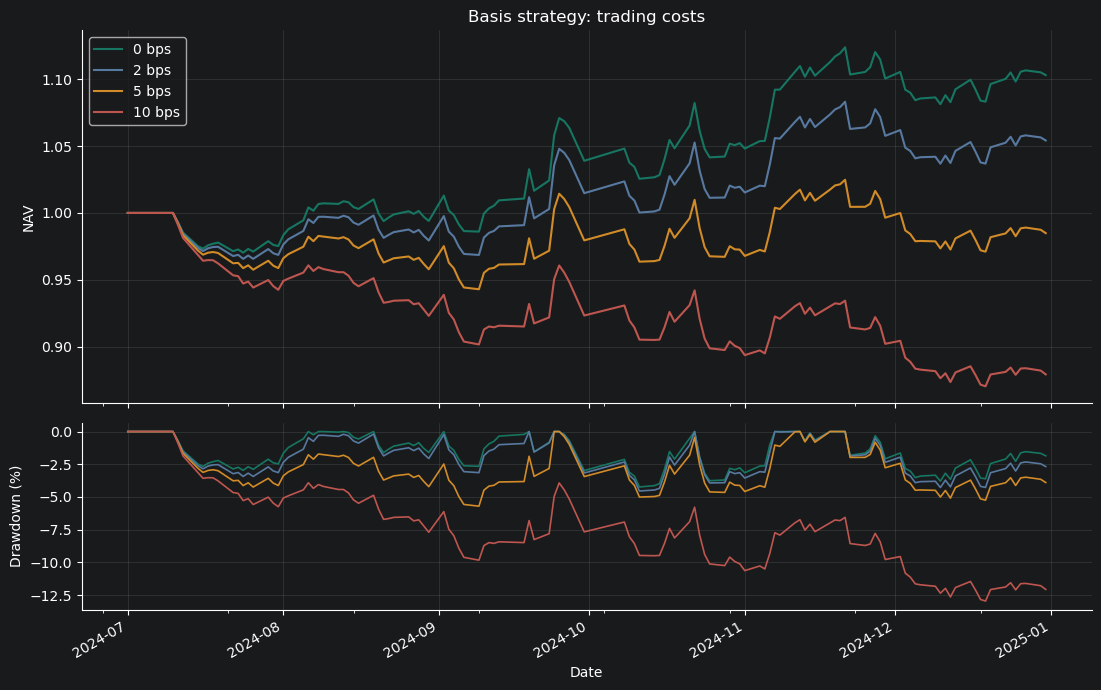

         期末净值    区间收益   最大回撤
0 bps  1.1031  10.31%  4.24%
2 bps  1.0542   5.42%  4.55%
5 bps  0.9849  -1.51%  5.71%
10 bps 0.8793 -12.07% 12.96%


In [6]:
cost_levels = [0, 2, 5, 10]
nav = pd.DataFrame(index=dates)
net_returns = pd.DataFrame(index=dates[1:])
for bps in cost_levels:
    daily_net = gross_return - turnover * bps / 10_000
    # 收益记在持有期结束日，最前面保留初始净值1。
    daily_net.index = dates[1:]
    label = f'{bps} bps'
    net_returns[label] = daily_net
    nav[label] = pd.concat([
        pd.Series([1.], index=dates[:1]),
        (1 + daily_net).cumprod(),
    ])

drawdown = nav.div(nav.cummax()) - 1
colors = ['#167662', '#57799f', '#d18b28', '#be5650']
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})
nav.plot(ax=axes[0], color=colors, linewidth=1.5, title='Basis strategy: trading costs')
(drawdown * 100).plot(ax=axes[1], color=colors, linewidth=1.2, legend=False)
axes[0].set_ylabel('NAV')
axes[1].set_ylabel('Drawdown (%)')
axes[1].set_xlabel('Date')
for ax in axes:
    ax.grid(alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    '期末净值': nav.iloc[-1],
    '区间收益': nav.iloc[-1] - 1,
    '最大回撤': -drawdown.min(),
})
print(summary.to_string(formatters={
    '期末净值': '{:.4f}'.format,
    '区间收益': '{:.2%}'.format,
    '最大回撤': '{:.2%}'.format,
}))


## 看完以后

先确认0 bps曲线与基差入门篇一致，再看成本升高后净值和回撤怎样变化。图上两条净值的最终差额包含复利路径的影响，不能直接当成手续费总额。

这里只用半年样例，不展示短区间外推的年化数字。预热长度、品种范围和执行口径与视频完整研究不同，两边的收益不能直接比较。

可以试着修改 cost_levels，观察曲线。想减少交易，需要进一步改变持仓规则并重算，不能只把成本率调低。
